# 03 · Doubly robust estimation (AIPW)

Notebook 01 modelled the outcome; notebook 02 modelled treatment assignment. **Augmented IPW**
uses both: it starts from the outcome-model estimate and adds an IPW-weighted correction of that
model's residuals.

$$\psi_i = \hat\mu_1(x_i)-\hat\mu_0(x_i) + \frac{d_i\,(y_i-\hat\mu_1(x_i))}{\hat e(x_i)} - \frac{(1-d_i)(y_i-\hat\mu_0(x_i))}{1-\hat e(x_i)}, \qquad \widehat{ATE}=\bar\psi$$

**Double robustness:** the estimate is consistent if *either* the outcome models *or* the propensity
model is correct. $\psi_i$ is also the (estimated) **influence function**, so the standard error is just
$\text{sd}(\psi)/\sqrt n$.

**Cross-fitting:** nuisance models are fit on K−1 folds and evaluated on the held-out fold. That is
irrelevant for linear models but essential once you use flexible ML (notebook 05).

**Library check:** `doubleml.DoubleMLIRM` with the same learners, the same folds and the same propensity clipping.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # silence library deprecation/progress chatter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import KFold
import doubleml as dml

import causalsim as cs
from causalsim.plotting import use_style, truth_line

use_style()
X_cols = ["X1", "X2", "X3"]

## 1. From scratch: cross-fitted AIPW

In [2]:
def aipw(X, d, y, outcome_model, propensity_model, n_folds=5, clip=0.01, seed=1, folds=None):
    """Cross-fitted AIPW. Returns (ate, se, folds, nuisance predictions)."""
    n = len(y)
    if folds is None:
        folds = list(KFold(n_folds, shuffle=True, random_state=seed).split(X))
    mu0, mu1, e = np.zeros(n), np.zeros(n), np.zeros(n)
    for train, test in folds:
        for arm, mu in ((0, mu0), (1, mu1)):
            idx = train[d[train] == arm]
            mu[test] = outcome_model().fit(X[idx], y[idx]).predict(X[test])
        e[test] = propensity_model().fit(X[train], d[train]).predict_proba(X[test])[:, 1]
    e = np.clip(e, clip, 1 - clip)
    psi = mu1 - mu0 + d * (y - mu1) / e - (1 - d) * (y - mu0) / (1 - e)
    ate = psi.mean()
    se = psi.std() / np.sqrt(n)
    return ate, se, folds, dict(mu0=mu0, mu1=mu1, e=e)


OLS = LinearRegression
LOGIT = lambda: LogisticRegression(penalty=None, max_iter=2_000)

sim = cs.confounded_binary(n=5_000, ate=2.0, seed=0)
df = sim.data
X, D, Y = df[X_cols].to_numpy(), df.D.to_numpy(), df.Y.to_numpy()

ate, se, folds, nuis = aipw(X, D, Y, OLS, LOGIT)
print(f"AIPW: {ate:.4f} ± {1.96*se:.4f}   (truth {sim.truth['ate']})")

AIPW: 1.9957 ± 0.0709   (truth 2.0)


## 2. Library check: DoubleML

`DoubleMLIRM` with `score="ATE"` is exactly this estimator. To get an *identical* number:
same learners, same folds (`set_sample_splitting`), and the same propensity clipping (DoubleML's default is
truncation at 0.01).

In [3]:
dml_data = dml.DoubleMLData(df, y_col="Y", d_cols="D", x_cols=X_cols)
irm = dml.DoubleMLIRM(dml_data, OLS(), LOGIT(), n_folds=5, draw_sample_splitting=False)
irm.set_sample_splitting([folds])
irm.fit()

np.testing.assert_allclose(ate, irm.coef[0], rtol=1e-8)
np.testing.assert_allclose(se, irm.se[0], rtol=1e-8)
assert abs(ate - sim.truth["ate"]) < 0.1
print(f"✓ matches DoubleMLIRM exactly: coef {irm.coef[0]:.6f}, se {irm.se[0]:.6f}")

✓ matches DoubleMLIRM exactly: coef 1.995747, se 0.036186


## 3. Double robustness in action

Four worlds. In each we fit **linear** outcome models and a **logistic** propensity model, so:

| world | outcome model | propensity model |
|---|---|---|
| A: linear outcome, logistic propensity | ✓ correct | ✓ correct |
| B: non-linear outcome | ✗ wrong | ✓ correct |
| C: non-linear propensity | ✓ correct | ✗ wrong |
| D: both non-linear | ✗ wrong | ✗ wrong |

Prediction: g-computation fails in B and D; IPW fails in C and D; AIPW fails only in D.

In [4]:
def compare(sim):
    d = sim.data
    Xv, Dv, Yv = d[X_cols].to_numpy(), d.D.to_numpy(), d.Y.to_numpy()
    a, _, _, nu = aipw(Xv, Dv, Yv, OLS, LOGIT)
    g = np.mean(nu["mu1"] - nu["mu0"])  # cross-fitted g-computation
    e = nu["e"]
    w1, w0 = Dv / e, (1 - Dv) / (1 - e)
    hajek = np.sum(w1 * Yv) / w1.sum() - np.sum(w0 * Yv) / w0.sum()
    return {"g-computation": g, "IPW (Hájek)": hajek, "AIPW": a}

worlds = {
    "A: both correct": dict(),
    "B: outcome wrong": dict(nonlinear_outcome=True),
    "C: propensity wrong": dict(nonlinear_propensity=True),
    "D: both wrong": dict(nonlinear_outcome=True, nonlinear_propensity=True),
}
res = pd.DataFrame({k: compare(cs.confounded_binary(n=50_000, seed=11, **kw)) for k, kw in worlds.items()}).T
(res - 2.0).round(3).rename(columns=lambda c: f"bias: {c}")

,bias: g-computation,bias: IPW (Hájek),bias: AIPW
A: both correct,0.008,0.006,0.011
B: outcome wrong,0.112,-0.004,-0.003
C: propensity wrong,0.005,-0.610,0.002
D: both wrong,-0.316,-0.667,-0.048


## 4. Do the confidence intervals cover?

A correct standard error should give ~95% coverage over repeated datasets. This checks the
influence-function variance formula, which is easy to get subtly wrong.

95% CI coverage over 200 datasets: 97.5%


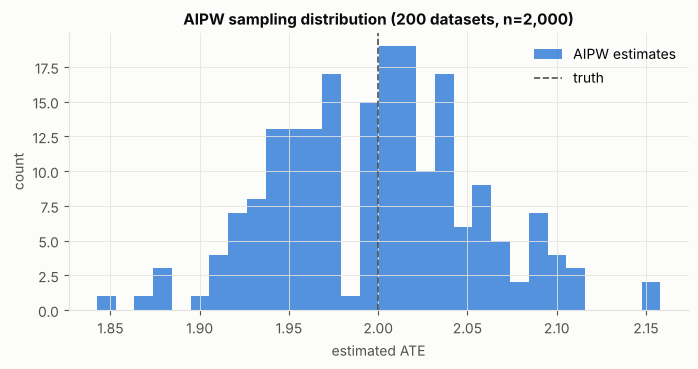

In [5]:
cover, ests = [], []
for s in range(200):
    d = cs.confounded_binary(n=2_000, seed=500 + s).data
    a, sd, _, _ = aipw(d[X_cols].to_numpy(), d.D.to_numpy(), d.Y.to_numpy(), OLS, LOGIT, seed=s)
    ests.append(a)
    cover.append(abs(a - 2.0) <= 1.96 * sd)
print(f"95% CI coverage over 200 datasets: {np.mean(cover):.1%}")

fig, ax = plt.subplots()
ax.hist(ests, bins=30, alpha=0.8, label="AIPW estimates")
truth_line(ax, 2.0)
ax.set(title="AIPW sampling distribution (200 datasets, n=2,000)", xlabel="estimated ATE", ylabel="count")
ax.legend()
plt.show()

**What to notice**

- In worlds B and C, AIPW stays near zero bias while the single-model estimator that is wrong does not.
- World D: double robustness is not magic. With *both* models wrong, AIPW is biased too. Here the bias is much
  smaller than either single-model estimator's, but nothing guarantees that. The fix is better nuisance models (ML),
  which is exactly what double ML adds, together with cross-fitting.
- The CI line in section 1 prints the 95% half-width ($1.96 \times$ SE); DoubleML reports the SE itself.
- Coverage close to 95% means the influence-function SE is working.

**Exercises**
1. Replace `LinearRegression` / `LogisticRegression` with gradient boosting in world D. Does the bias go away?
   Now set `n_folds=1`-style in-sample fitting (fit and predict on the same data). What happens to coverage?
2. Change `clip` from 0.01 to 0.1 under poor overlap (`confounding=3`). What do you trade?
3. Derive the ATT version of the AIPW score and check it against `DoubleMLIRM(score="ATTE")`.